# Q6 — Hồ sơ hương vị theo châu lục

| Trường | Nội dung |
| --- | --- |
| Câu hỏi | Bốn châu lục North America, South America, Asia và Africa có hồ sơ hương vị khác nhau như thế nào? Thuộc tính nào tạo khác biệt lớn nhất và xếp hạng đó thay đổi ra sao khi bỏ Uniformity, Clean.Cup và Sweetness? |
| Loại | non-ML |
| Tiêu chí chiều sâu | D2, D3, D6 |
| Cột dữ liệu sử dụng | `REC_ID`, `Species`, `Continent.of.Origin` và chín thuộc tính cảm quan trong `SCORE_COLS` |

## 1. Preprocessing

### a. Nguồn dữ liệu và phạm vi

Đọc bảng `Coffee_Qlty.csv`, trong đó mỗi dòng là một lô cà phê và chín cột trong `SCORE_COLS` là điểm cảm quan cần so sánh. Các thuộc tính gồm Aroma, Flavor, Aftertaste, Acidity, Body, Balance, Uniformity, Clean.Cup và Sweetness, cùng nằm trên thang điểm 0–10.

Đoạn xử lý dưới đây chuẩn bị bảng CQI gốc và danh sách chín thuộc tính để dùng thống nhất ở các bước sau. Việc chọn mẫu, chuyển dạng và chuẩn hóa sẽ dựa trên cùng bảng này, giúp các bảng thống kê và hai biểu đồ có chung nguồn dữ liệu.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

cwd = Path.cwd()
root = next(path for path in (cwd, *cwd.parents) if (path / "src" / "config.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.config import RAW, SCORE_COLS

cqi = pd.read_csv(RAW / "Coffee_Qlty.csv", keep_default_na=False, na_values=[""])

### b. Mẫu phân tích

Chọn các lô Arabica, bỏ bản ghi giữ chỗ 1310 và chỉ giữ North America, South America, Asia, Africa. Lô thiếu châu lục và Oceania được loại vì câu hỏi chỉ so sánh bốn nhóm này. Dùng toàn bộ năm thu hoạch, kể cả lô thiếu năm, vì bước phân tích chỉ cần điểm cảm quan và châu lục.

Theo quy ước của nhóm, giữ lô 1306 có `Clean.Cup = 0` và cả hai lô 721, 742 trong mẫu chính. Bảng đầu ra cho biết số lô của mỗi châu lục, giúp người đọc hiểu cơ sở của các giá trị trung bình sau này. Mẫu có **1.308 lô**, gồm 662 ở North America, 326 ở South America, 168 ở Asia và 152 ở Africa.

In [2]:
continents = ["North America", "South America", "Asia", "Africa"]
arabica = cqi.loc[cqi["Species"].eq("Arabica")]
without_placeholder = arabica.loc[arabica["REC_ID"].ne(1310)]
with_continent = without_placeholder.loc[without_placeholder["Continent.of.Origin"].notna()]
q6_lots = with_continent.loc[with_continent["Continent.of.Origin"].isin(continents)].copy()

display(
    q6_lots["Continent.of.Origin"].value_counts().reindex(continents)
    .rename_axis("Continent.of.Origin").reset_index(name="Số lô")
)
assert q6_lots["REC_ID"].is_unique

,Continent.of.Origin,Số lô
0,North America,662
1,South America,326
2,Asia,168
3,Africa,152


## 2. Analysis

### a. Melt chín thuộc tính

Ở bảng gốc, mỗi lô có chín cột điểm. Chuyển bảng sang dạng dài bằng `melt` để mỗi dòng chứa điểm của một thuộc tính tại một lô. Hai cột nhận diện `REC_ID` và `Continent.of.Origin` được lặp lại theo lô, còn tên thuộc tính và điểm được đưa vào `attribute` và `score`.

Kết quả là bảng `long_scores` có **11.772 dòng và bốn cột**, bằng 1.308 lô nhân chín thuộc tính. Kiểm tra số dòng và tính duy nhất của cặp lô–thuộc tính để bảo đảm phép chuyển dạng bảo toàn điểm. Bảng này được dùng ngay sau đó để tổng hợp theo châu lục và thuộc tính.

In [3]:
long_scores = q6_lots.melt(
    id_vars=["REC_ID", "Continent.of.Origin"],
    value_vars=SCORE_COLS,
    var_name="attribute",
    value_name="score",
)
assert len(long_scores) == len(q6_lots) * len(SCORE_COLS)
assert not long_scores.duplicated(["REC_ID", "attribute"]).any()

### b. Median điểm gốc

Từ bảng dài, gom các dòng có cùng châu lục và thuộc tính rồi lấy median điểm. Sau đó đặt bốn châu lục thành hàng và chín thuộc tính thành cột. Mỗi ô của `pivot_table` cho biết điểm ở giữa phân bố của một thuộc tính trong nhóm lô thuộc châu lục đó.

Bảng đầu ra có kích thước **4 × 9**, giữ đơn vị điểm gốc trên thang 0–10 và thứ tự thuộc tính thống nhất. Bảng giúp nhận biết mức điểm điển hình trước chuẩn hóa, nhất là các cột có median sát 10. Phần xếp hạng tiếp theo dùng mean z-score để so độ chênh theo độ phân tán của từng thuộc tính.

In [4]:
median_profile = long_scores.pivot_table(
    index="Continent.of.Origin", columns="attribute", values="score", aggfunc="median",
).reindex(index=continents, columns=SCORE_COLS)
assert median_profile.shape == (len(continents), len(SCORE_COLS))
print("Median điểm theo châu lục và thuộc tính")
display(
    median_profile.rename_axis(columns=None).reset_index()
    .style.format({column: "{:.2f}" for column in SCORE_COLS})
    .set_properties(**{"text-align": "center"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}])
    .hide(axis="index")
)

Median điểm theo châu lục và thuộc tính


Continent.of.Origin,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness
North America,7.50,7.50,7.33,7.50,7.50,7.50,10.00,10.00,10.00
South America,7.58,7.58,7.50,7.58,7.58,7.58,10.00,10.00,10.00
Asia,7.50,7.50,7.42,7.46,7.50,7.50,10.00,10.00,10.00
Africa,7.75,7.75,7.58,7.71,7.67,7.67,10.00,10.00,10.00


### c. Chuẩn hóa z-score

Tính mean và độ lệch chuẩn mẫu cho từng thuộc tính trên toàn bộ 1.308 lô của bốn châu lục, với mỗi lô có cùng trọng số. Với điểm của từng lô, lấy điểm trừ mean rồi chia cho độ lệch chuẩn của thuộc tính đó. Dùng `ddof=1` và kiểm tra độ lệch chuẩn dương trước khi chia.

Kết quả là bảng `z_scores` có cùng số lô và chín cột điểm chuẩn hóa. Z-score dương thể hiện điểm cao hơn mean chung, âm thể hiện thấp hơn, còn 0 là ngang mean chung. Đơn vị là độ lệch chuẩn của chính thuộc tính. Chuẩn hóa trên mẫu chung giúp các châu lục cùng được so với một mốc, đồng thời hỗ trợ so độ chênh của các thuộc tính có độ phân tán khác nhau.

In [5]:
score_means = q6_lots[SCORE_COLS].mean()
score_stds = q6_lots[SCORE_COLS].std(ddof=1)
if score_stds.isna().any() or not score_stds.gt(0).all():
    raise ValueError("Z-score cần độ lệch chuẩn dương cho từng thuộc tính")

z_scores = (q6_lots[SCORE_COLS] - score_means) / score_stds

### d. Mean z-score và xếp hạng

Lấy mean z-score của các lô theo từng châu lục để tạo hồ sơ chuẩn hóa 4 × 9. Mỗi ô biểu thị mức điểm trung bình của châu lục cao hoặc thấp hơn mean chung bao nhiêu độ lệch chuẩn. Chẳng hạn, mean z-score của Aftertaste bằng 0,62 có nghĩa điểm hậu vị trung bình cao hơn mức chung khoảng 0,62 độ lệch chuẩn.

Với mỗi thuộc tính, lấy mean z-score cao nhất trừ thấp nhất giữa bốn châu lục để tính `spread`. Spread lớn hơn thể hiện khoảng cách giữa hai đầu lớn hơn. Xếp hạng theo spread giảm dần, dùng số chưa làm tròn và cho cùng hạng nếu bằng nhau.

Đầu ra gồm bảng mean z-score và bảng xếp hạng. Bảng thứ nhất phục vụ mô tả hồ sơ từng châu lục; bảng thứ hai xác định thuộc tính tạo độ chênh lớn nhất. Cả hai sẽ được dùng làm mốc cho kiểm tra khi bỏ ba thuộc tính sát trần và khi bỏ lô trùng.

In [6]:
z_profile = z_scores.groupby(q6_lots["Continent.of.Origin"]).mean().reindex(continents)
attribute_ranking = pd.DataFrame({
    "Mean z-score thấp nhất": z_profile.min(),
    "Mean z-score cao nhất": z_profile.max(),
})
attribute_ranking["spread"] = (
    attribute_ranking["Mean z-score cao nhất"] - attribute_ranking["Mean z-score thấp nhất"]
)
attribute_ranking["Hạng"] = attribute_ranking["spread"].rank(
    ascending=False, method="min"
).astype(int)
attribute_ranking = attribute_ranking.sort_values(
    "spread", ascending=False, kind="stable"
).rename_axis("Thuộc tính").reset_index()
attribute_ranking = attribute_ranking[
    ["Hạng", "Thuộc tính", "Mean z-score thấp nhất", "Mean z-score cao nhất", "spread"]
]
assert z_profile.shape == (len(continents), len(SCORE_COLS))

print("Mean z-score theo châu lục và thuộc tính")
display(
    z_profile.rename_axis(columns=None).reset_index()
    .style.format({column: "{:.3f}" for column in SCORE_COLS})
    .set_properties(**{"text-align": "center"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}])
    .hide(axis="index")
)
print("Xếp hạng độ chênh giữa bốn châu lục")
display(
    attribute_ranking.style.format({
        "Mean z-score thấp nhất": "{:.4f}", "Mean z-score cao nhất": "{:.4f}", "spread": "{:.4f}",
    })
    .set_properties(**{"text-align": "center"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}])
    .hide(axis="index")
)

Mean z-score theo châu lục và thuộc tính
Xếp hạng độ chênh giữa bốn châu lục


Continent.of.Origin,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness
North America,-0.173,-0.196,-0.264,-0.096,-0.208,-0.225,-0.148,-0.127,-0.078
South America,0.139,0.194,0.251,0.020,0.228,0.324,0.125,0.073,0.084
Asia,-0.122,-0.089,-0.010,-0.234,-0.086,-0.180,0.138,0.187,0.065
Africa,0.588,0.536,0.621,0.633,0.511,0.484,0.226,0.190,0.090


Hạng,Thuộc tính,Mean z-score thấp nhất,Mean z-score cao nhất,spread
1,Aftertaste,-0.2636,0.6215,0.8851
2,Acidity,-0.2337,0.6330,0.8667
3,Aroma,-0.1726,0.5882,0.7609
4,Flavor,-0.1957,0.5359,0.7317
5,Body,-0.2077,0.5111,0.7187
6,Balance,-0.2251,0.4835,0.7086
7,Uniformity,-0.1483,0.2257,0.3739
8,Clean.Cup,-0.1270,0.1897,0.3167
9,Sweetness,-0.0784,0.0899,0.1684


## 3. Robustness

### a. Bỏ ba thuộc tính sát trần điểm

Trước hết, đếm số lô đạt đúng 10 điểm ở Uniformity, Clean.Cup và Sweetness, rồi chia cho số điểm hợp lệ của từng thuộc tính. Bảng tỷ lệ cho biết cơ sở để xem ba thuộc tính này là sát trần điểm. Sau đó bỏ ba cột, giữ nguyên mẫu lô và cách chuẩn hóa, rồi xếp hạng lại sáu thuộc tính còn lại.

Đầu ra gồm bảng tỷ lệ đạt 10 và bảng so sánh hạng, spread khi dùng chín hoặc sáu thuộc tính. Dấu gạch tại ba thuộc tính bị bỏ thể hiện các thuộc tính đó ra khỏi phép so sánh. Vì z-score được tính độc lập theo từng cột, spread của sáu cột còn lại giữ nguyên khi chỉ bỏ cột. Khi đọc bảng, kiểm tra thuộc tính dẫn đầu và thứ tự các thuộc tính còn hiện diện.

In [7]:
ceiling_columns = ["Uniformity", "Clean.Cup", "Sweetness"]
retained_columns = [column for column in SCORE_COLS if column not in ceiling_columns]
ceiling_audit = pd.DataFrame({
    "Số điểm hợp lệ": q6_lots[ceiling_columns].count(),
    "Số lô đạt 10 điểm": q6_lots[ceiling_columns].eq(10).sum(),
})
ceiling_audit["Tỷ lệ đạt 10 điểm"] = (
    ceiling_audit["Số lô đạt 10 điểm"] / ceiling_audit["Số điểm hợp lệ"]
)
display(
    ceiling_audit.rename_axis("Thuộc tính").reset_index()
    .style.format({"Tỷ lệ đạt 10 điểm": "{:.2%}"})
    .set_properties(**{"text-align": "center"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}])
    .hide(axis="index")
)

z_profile_six = z_profile[retained_columns]
spread_six = z_profile_six.max() - z_profile_six.min()
baseline_spread = attribute_ranking.set_index("Thuộc tính")["spread"]
column_robustness = pd.DataFrame({
    "Hạng 9 thuộc tính": baseline_spread.rank(ascending=False, method="min"),
    "Hạng 6 thuộc tính": spread_six.rank(ascending=False, method="min"),
    "Spread 9 thuộc tính": baseline_spread,
    "Spread 6 thuộc tính": spread_six,
}).sort_values("Hạng 9 thuộc tính")
display(
    column_robustness.rename_axis("Thuộc tính").reset_index()
    .style.format({
        "Hạng 9 thuộc tính": "{:.0f}", "Hạng 6 thuộc tính": "{:.0f}",
        "Spread 9 thuộc tính": "{:.4f}", "Spread 6 thuộc tính": "{:.4f}",
    }, na_rep="—")
    .set_properties(**{"text-align": "center"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}])
    .hide(axis="index")
)

Thuộc tính,Số điểm hợp lệ,Số lô đạt 10 điểm,Tỷ lệ đạt 10 điểm
Uniformity,1308,1127,86.16%
Clean.Cup,1308,1193,91.21%
Sweetness,1308,1216,92.97%


Thuộc tính,Hạng 9 thuộc tính,Hạng 6 thuộc tính,Spread 9 thuộc tính,Spread 6 thuộc tính
Aftertaste,1,1,0.8851,0.8851
Acidity,2,2,0.8667,0.8667
Aroma,3,3,0.7609,0.7609
Flavor,4,4,0.7317,0.7317
Body,5,5,0.7187,0.7187
Balance,6,6,0.7086,0.7086
Uniformity,7,—,0.3739,—
Clean.Cup,8,—,0.3167,—
Sweetness,9,—,0.1684,—


### b. Bỏ lô trùng 742

Kiểm tra hai lô 721, 742 giống nhau ở mọi cột ngoài mã nhận diện. Sau đó bỏ lô 742, tính lại mean và độ lệch chuẩn trên mẫu còn lại, rồi tính lại z-score, mean theo châu lục và spread. Việc tính lại các tham số giúp phép so sánh phản ánh đầy đủ tác động của việc loại một lô.

Bảng số lô cho biết mẫu giảm từ **1.308 xuống 1.307 lô**, với Asia giảm một lô. Bảng tiếp theo đặt hạng và spread trước, sau cạnh nhau, kèm mức thay đổi spread tính bằng giá trị mới trừ giá trị cũ. Cần xem thứ hạng có đổi và các giá trị dịch chuyển bao nhiêu để đánh giá kết quả có phụ thuộc vào việc giữ cặp trùng hay không.

In [8]:
duplicate_pair = q6_lots.loc[q6_lots["REC_ID"].isin([721, 742])]
assert len(duplicate_pair) == 2
assert duplicate_pair.drop(columns="REC_ID").iloc[0].equals(
    duplicate_pair.drop(columns="REC_ID").iloc[1]
)

without_742 = q6_lots.loc[q6_lots["REC_ID"].ne(742)]
reduced_stds = without_742[SCORE_COLS].std(ddof=1)
if reduced_stds.isna().any() or not reduced_stds.gt(0).all():
    raise ValueError("Mẫu bỏ lô trùng cần độ lệch chuẩn dương để chuẩn hóa")
z_without_742 = (
    without_742[SCORE_COLS] - without_742[SCORE_COLS].mean()
) / reduced_stds
profile_without_742 = z_without_742.groupby(
    without_742["Continent.of.Origin"]
).mean().reindex(continents)
spread_without_742 = profile_without_742.max() - profile_without_742.min()

sample_comparison = pd.DataFrame({
    "Giữ hai lô": q6_lots["Continent.of.Origin"].value_counts(),
    "Bỏ lô 742": without_742["Continent.of.Origin"].value_counts(),
}).reindex(continents)
sample_comparison["Thay đổi số lô"] = sample_comparison["Bỏ lô 742"] - sample_comparison["Giữ hai lô"]
display(sample_comparison.rename_axis("Châu lục").reset_index())

duplicate_robustness = pd.DataFrame({
    "Hạng mẫu chính": baseline_spread.rank(ascending=False, method="min"),
    "Hạng bỏ lô 742": spread_without_742.rank(ascending=False, method="min"),
    "Spread mẫu chính": baseline_spread,
    "Spread bỏ lô 742": spread_without_742,
})
duplicate_robustness["Thay đổi spread"] = (
    duplicate_robustness["Spread bỏ lô 742"] - duplicate_robustness["Spread mẫu chính"]
)
duplicate_robustness = duplicate_robustness.sort_values("Hạng mẫu chính")
display(
    duplicate_robustness.rename_axis("Thuộc tính").reset_index()
    .style.format({
        "Hạng mẫu chính": "{:.0f}", "Hạng bỏ lô 742": "{:.0f}",
        "Spread mẫu chính": "{:.6f}", "Spread bỏ lô 742": "{:.6f}",
        "Thay đổi spread": "{:+.6f}",
    })
    .set_properties(**{"text-align": "center"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "center")]}])
    .hide(axis="index")
)

,Châu lục,Giữ hai lô,Bỏ lô 742,Thay đổi số lô
0,North America,662,662,0
1,South America,326,326,0
2,Asia,168,167,-1
3,Africa,152,152,0


Thuộc tính,Hạng mẫu chính,Hạng bỏ lô 742,Spread mẫu chính,Spread bỏ lô 742,Thay đổi spread
Aftertaste,1,1,0.885067,0.884754,-0.000313
Acidity,2,2,0.866692,0.867036,+0.000344
Aroma,3,3,0.760891,0.760614,-0.000277
Flavor,4,4,0.731664,0.731386,-0.000279
Body,5,5,0.718724,0.718450,-0.000273
Balance,6,6,0.708637,0.708367,-0.000270
Uniformity,7,7,0.373948,0.373820,-0.000128
Clean.Cup,8,8,0.316682,0.316567,-0.000115
Sweetness,9,9,0.168363,0.168301,-0.000062


## 4. Results

### a. Heatmap

Heatmap trình bày bảng mean z-score với châu lục ở hàng và thuộc tính ở cột. Mỗi ô có giá trị số và màu thể hiện mức cao hoặc thấp so với mean chung. Thang màu đối xứng quanh 0 để độ lệch dương và âm được thể hiện trên cùng mức độ.

Đọc theo hàng để nhận biết hồ sơ một châu lục, rồi đọc theo cột để so sánh bốn châu lục ở cùng một thuộc tính. Khoảng cách giữa ô cao nhất và thấp nhất của mỗi cột chính là spread trong bảng xếp hạng. Biểu đồ này nối câu hỏi về khác biệt hồ sơ với câu hỏi về thuộc tính có độ chênh lớn nhất.

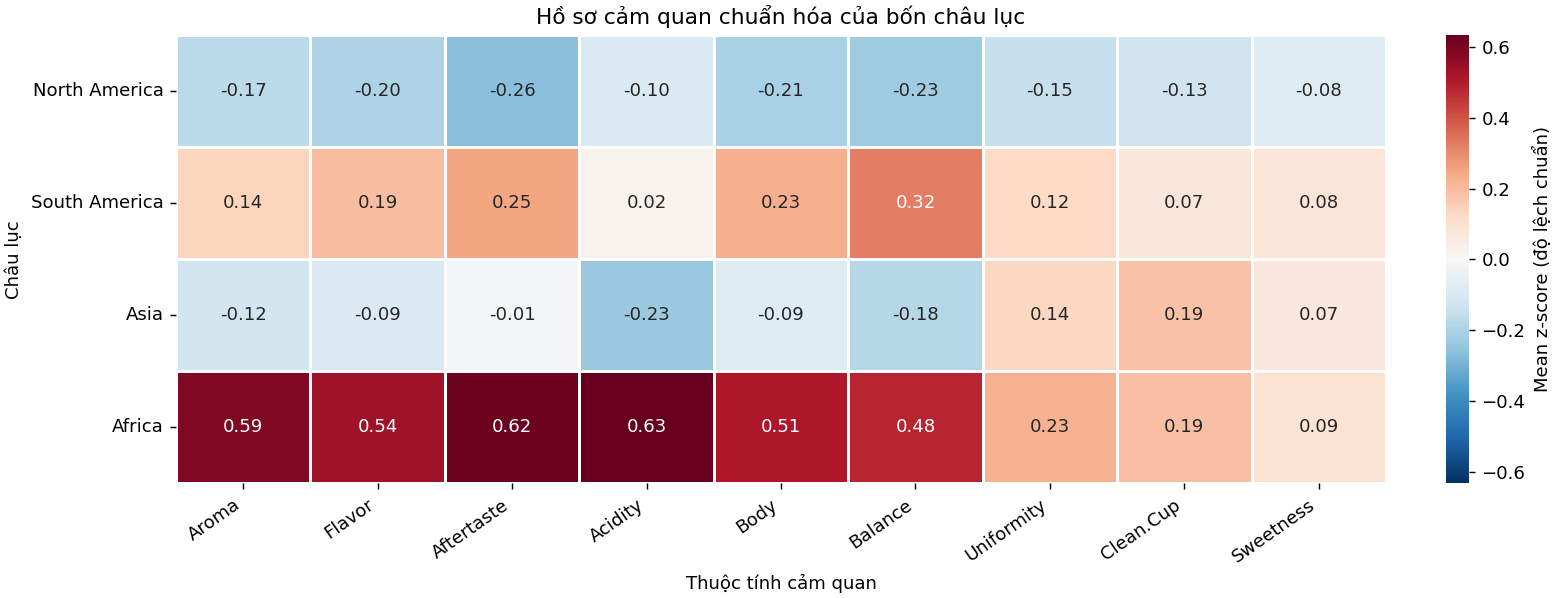

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

color_limit = z_profile.abs().to_numpy().max()
fig, ax = plt.subplots(figsize=(12, 4.6), layout="constrained")
sns.heatmap(
    z_profile, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    vmin=-color_limit, vmax=color_limit, linewidths=0.6,
    cbar_kws={"label": "Mean z-score (độ lệch chuẩn)"}, ax=ax,
)
ax.set(
    title="Hồ sơ cảm quan chuẩn hóa của bốn châu lục",
    xlabel="Thuộc tính cảm quan", ylabel="Châu lục",
)
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.show()

### b. Profile theo châu lục

Biểu đồ dùng cùng mean z-score với heatmap nhưng thể hiện mỗi châu lục bằng một đường qua chín thuộc tính. Màu và kiểu đường phân biệt các nhóm. Trục X liệt kê thuộc tính cảm quan, trục Y là mean z-score tính bằng độ lệch chuẩn, còn đường ngang tại 0 biểu thị mean chung của mẫu.

So sánh các đường tại cùng một thuộc tính để thấy châu lục nào được chấm cao hơn hoặc thấp hơn mức chung. Quan sát những vị trí các đường tách xa hoặc gần nhau để đối chiếu với spread. Các đoạn nối hỗ trợ theo dõi hình dạng hồ sơ qua các thuộc tính. Heatmap cung cấp con số trên từng ô, còn profile giúp nhìn tổng thể vị trí tương đối của bốn châu lục.

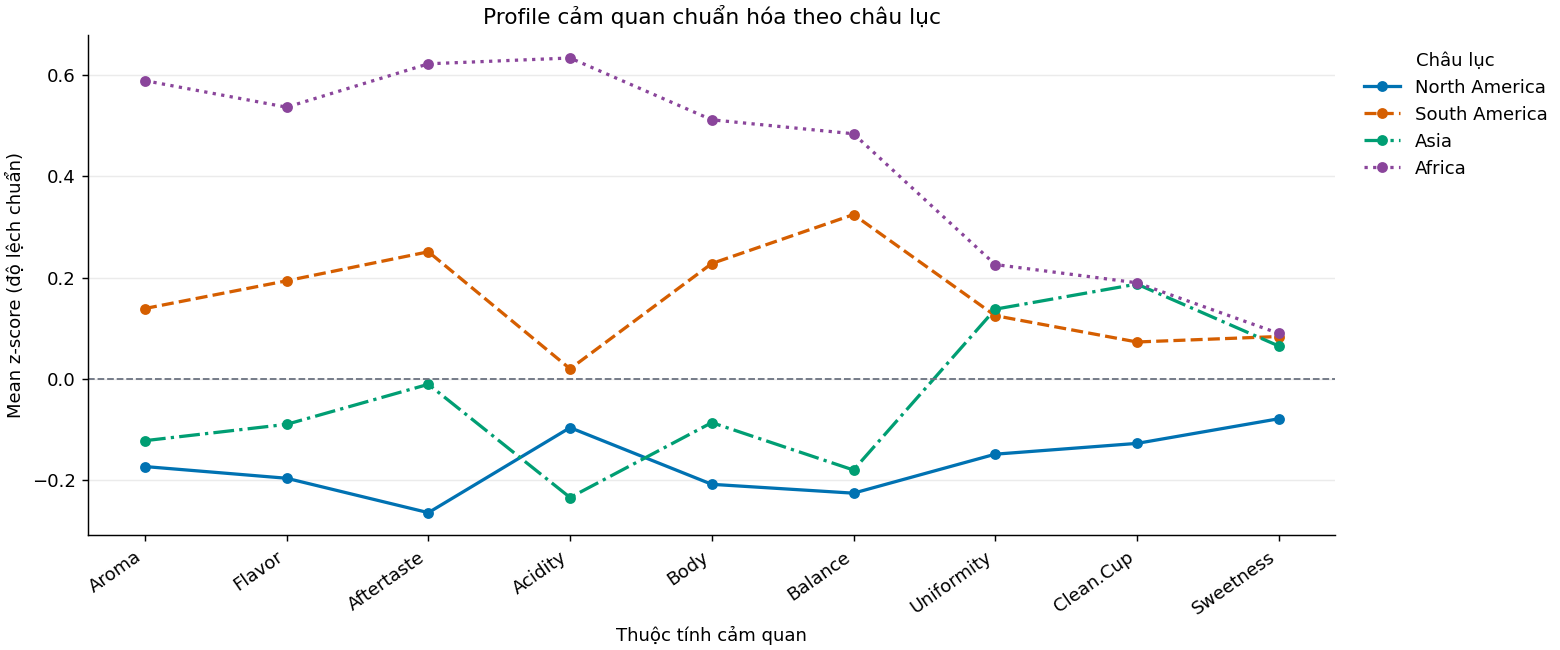

In [10]:
continent_colors = {
    "North America": "#0072B2", "South America": "#D55E00",
    "Asia": "#009E73", "Africa": "#8A459B",
}
line_styles = ["-", "--", "-.", ":"]
fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
for continent, line_style in zip(continents, line_styles):
    ax.plot(
        range(len(SCORE_COLS)), z_profile.loc[continent, SCORE_COLS],
        color=continent_colors[continent], linestyle=line_style,
        marker="o", markersize=5, linewidth=1.8, label=continent,
    )
ax.axhline(0, color="#6B7280", linewidth=1, linestyle="--")
ax.set_xticks(range(len(SCORE_COLS)), SCORE_COLS, rotation=35, ha="right")
ax.set(
    title="Profile cảm quan chuẩn hóa theo châu lục",
    xlabel="Thuộc tính cảm quan", ylabel="Mean z-score (độ lệch chuẩn)",
)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Châu lục", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
plt.show()

### c. Trả lời câu hỏi nghiên cứu

**Khác biệt hồ sơ cảm quan giữa bốn châu lục**

Trong mẫu Arabica được phân tích, biểu đồ profile và heatmap cho thấy bốn châu lục có hồ sơ điểm cảm quan khác nhau. Africa có mean z-score cao hơn mean chung của mẫu ở cả chín thuộc tính và cao nhất trong bốn châu lục. Các thuộc tính nổi bật gồm `Aroma`, `Acidity` và `Aftertaste`, với mean z-score lần lượt khoảng **0,5882**, **0,6330** và **0,6215**. Trong khi đó thấp nhất là Sweetness với 0,09 nhưng vẫn là châu lục có mean z-score ở thuộc tính Sweetness cao nhất trong bốn châu lục.

South America cũng có mean z-score dương ở cả chín thuộc tính, trong đó cao nhất là `Balance` với khoảng **0,3242**. Đến với Asia thì có sự khác biệt so với các châu lục khác khi Asia có mean z-score các thuộc tính trải từ âm sang dương ở chín thuộc tính. Asia có mean z-score dương ở `Uniformity`, `Clean.Cup` và `Sweetness`, còn sáu thuộc tính khác thấp hơn mean chung. Cuối cùng là North America với mean z-score âm ở cả chín thuộc tính, thấp nhất ở `Aftertaste` với khoảng **−0,2636** và cao nhất ở Sweetness cũng chỉ khoảng **-0,08**.

**Thuộc tính có độ chênh lớn nhất và thứ hạng khi bỏ ba thuộc tính sát trần**

`Aftertaste` có độ chênh lớn nhất giữa bốn châu lục, với spread **0,8851** độ lệch chuẩn. Hai đầu của khoảng chênh là Africa với mean z-score khoảng **0,6215** và North America với khoảng **−0,2636**. Spread của `Aftertaste` lớn hơn thuộc tính đứng thứ hai là `Acidity` khoảng **0,0184** và lớn hơn thuộc tính thấp nhất là `Sweetness` khoảng **0,7167**.

Khi bỏ `Uniformity`, `Clean.Cup` và `Sweetness`, thứ tự sáu thuộc tính còn lại vẫn là **Aftertaste, Acidity, Aroma, Flavor, Body và Balance**. Spread của cả sáu thuộc tính giữ nguyên vì mỗi cột được chuẩn hóa riêng trên cùng một mẫu lô. `Balance` có spread thấp nhất trong tập sáu thuộc tính, khoảng **0,7086**, thay cho `Sweetness` trong bảng chín thuộc tính.

**Kết quả khi bỏ lô trùng 742**

Sau khi bỏ lô 742 và tính lại tham số chuẩn hóa trên 1.307 lô, cả chín thuộc tính giữ nguyên thứ hạng. Spread của tám thuộc tính giảm, với mức giảm lớn nhất khoảng **0,000313** ở `Aftertaste`. Riêng spread của `Acidity` tăng khoảng **0,000344**. Kết quả cho thấy thứ tự thuộc tính trong mẫu ít bị ảnh hưởng bởi số lượng lô trùng như thế này, sự ảnh hưởng lớn chỉ xảy ra khi số lượng lô trùng trong mẫu đạt con số rất lớn.